# Credit Risk & CDS Hazard Rate Bootstrapping

**Implementation of the ISDA Standard Model for Market Credit Default Swaps (CDS)**
- Bootstrapping piecewise-constant hazard rates $\lambda(t)$ and survival curves $S(t)$
- Cumulative Probability of Default (PD) extraction
- Multi-Name Gaussian Copula simulation for CDO / First-to-Default (FTD) baskets

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cds_bootstrapping_engine import CDSBootstrapper

## 1. Market Input Curve & Bootstrapping

In [2]:
maturities = [1, 2, 3, 4, 5]
spreads_bps = [29.0, 39.0, 46.0, 52.0, 57.0]
dfs = [0.9803, 0.9514, 0.9159, 0.8756, 0.8328]
R = 0.50  # 50% Recovery Rate

bootstrapper = CDSBootstrapper(recovery_rate=R)
results, S = bootstrapper.bootstrap(maturities, spreads_bps, dfs)
results

,Maturity (Years),Spread (bps),Discount Factor,Survival Probability,Cumulative Default Prob,Piecewise Hazard Rate,Hazard Rate (bps)
0,1.0,29.0,0.9803,0.994233,0.005767,0.005783,57.832448
1,2.0,39.0,0.9514,0.984505,0.015495,0.009833,98.326161
2,3.0,46.0,0.9159,0.972636,0.027364,0.012130,121.298581
3,4.0,52.0,0.8756,0.958824,0.041176,0.014302,143.024563
4,5.0,57.0,0.8328,0.943693,0.056307,0.015907,159.065555


## 2. Term Structure Visualizations

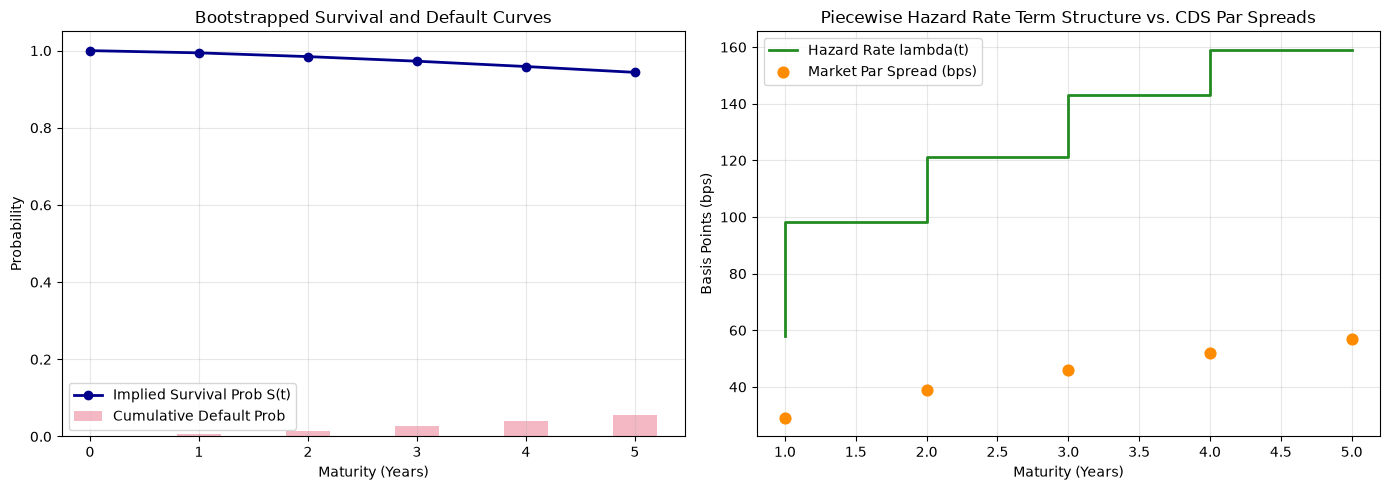

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot([0] + maturities, S, marker='o', color='darkblue', lw=2, label='Implied Survival Prob S(t)')
ax1.bar(maturities, results['Cumulative Default Prob'], width=0.4, alpha=0.3, color='crimson', label='Cumulative Default Prob')
ax1.set_title('Bootstrapped Survival and Default Curves')
ax1.set_xlabel('Maturity (Years)')
ax1.set_ylabel('Probability')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.step(maturities, results['Hazard Rate (bps)'], where='pre', color='forestgreen', lw=2, label='Hazard Rate lambda(t)')
ax2.scatter(maturities, spreads_bps, color='darkorange', s=60, zorder=5, label='Market Par Spread (bps)')
ax2.set_title('Piecewise Hazard Rate Term Structure vs. CDS Par Spreads')
ax2.set_xlabel('Maturity (Years)')
ax2.set_ylabel('Basis Points (bps)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Correlated Multi-Name Credit Basket Simulation

In [4]:
n_names = 5
rho = 0.35
corr_matrix = np.full((n_names, n_names), rho)
np.fill_diagonal(corr_matrix, 1.0)

sim = bootstrapper.simulate_copula_basket_defaults(
    results['Piecewise Hazard Rate'].values, maturities, corr_matrix, n_sims=50000
)
print(f"5-Year First-to-Default (FTD) Basket Probability: {sim['first_to_default_5y_prob']*100:.2f}%")
print(f"Average Individual 5-Year Default Rate: {np.mean(sim['5y_default_rate'])*100:.2f}%")

5-Year First-to-Default (FTD) Basket Probability: 20.67%
Average Individual 5-Year Default Rate: 5.66%
